#first generate dataset2_normal_then_control_meet_at_least_one_condition.csv, all sequences

In [ ]:
import numpy as np
import pandas as pd
import os


: 

In [2]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase']].sum(axis=1) > 0)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

# def merge_seqid_count(df, result_df, column_name):
#     result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
#     result_df = result_df.rename(columns={'qseqid_count': column_name})
#     return result_df

# # function to generate form and save the result
# def generate_and_save_result(names, df_dict, output_file):
#     all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
#     result_df = pd.DataFrame({'sequence': all_sequences})
    
#     for name in names:
#         df = df_dict[name]
#         result_df = merge_seqid_count(df, result_df, f'{name}')
#     print("result_df",result_df)
#     result_df.to_csv(os.path.join(base_path, output_file), index=False)

In [6]:
# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_with_match = initialize_dfs(total_names)
df_total = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)
read_csv_files(total_names, df_with_match, base_path, read_columns)

filter_dataframes(total_names, df_total, df_with_match)
for name in total_names:
    num_rows = len(df_with_match[name])
    num_row_all = len(df_total[name])
    percent = round(num_rows/num_row_all *100,2)
    print(f"DataFrame {name} has {percent}% lines.")

# print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_all_seuquences.csv")


DataFrame SRR18078869 has 30.45% lines.
DataFrame SRR18078868 has 31.26% lines.
DataFrame SRR18078867 has 26.76% lines.
DataFrame SRR18078872 has 21.87% lines.
DataFrame SRR18078871 has 24.34% lines.
DataFrame SRR18078870 has 30.2% lines.


In [1]:
import numpy as np
import pandas as pd
import os

# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    # filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)


In [2]:
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_all_seuquences.csv")


DataFrame SRR18078869 has 46023 lines.
DataFrame SRR18078868 has 59362 lines.
DataFrame SRR18078867 has 89985 lines.
DataFrame SRR18078872 has 60844 lines.
DataFrame SRR18078871 has 46533 lines.
DataFrame SRR18078870 has 85316 lines.
{'SRR18078869':                        sequence  qseqid_count
0          CCCACCCCCCGTCGCCTCCG           464
1           GGAGAAGCCGGCGGGAGCC         62586
2      CGGAGAAGCCGGCGGGAGCCCCGG         38168
3        TCCCGCCGTCGCCGTCCCCGCT           813
4           GCACCCGTAGCTCAGCTGG           351
...                         ...           ...
46018   AGGGAACGGGCTTGGCGGAATCA             1
46019      AGAGTTTGATCCTGGCTCAG             2
46020    CCGGTCGGGGGACGGATTGGGA             1
46021     CGAACGAGACTCTGGCATGCT             1
46022     CAACCGAGATTCCCCCAGTAG             1

[46023 rows x 2 columns], 'SRR18078868':                                  sequence  qseqid_count
0               CACTGACTGGAGGACCGAACCGACT             1
1      GCGTGAGTGAAGAAGGCCTTCGGGTTGTAAAGCT   

aaa
         index   0     1    2   3  4   5   6     7   8  ...  216600  216601  \
0  SRR18078869  11  1537  937  19  8  50  15  4825   6  ...       0       0   
1  SRR18078868   5    31   68  20  1   2  13   232  10  ...       0       0   
2  SRR18078867   4    64   39   0  0   0  10   415   0  ...       0       0   
3  SRR18078872   0     0    1   0  0   0   0     1   0  ...       0       0   
4  SRR18078871   0     1    1   0  0   0   0     0   0  ...       0       0   
5  SRR18078870   0     1    7   0  0   0   0     2   0  ...       0       0   

   216602  216603  216604  216605  216606  216607  216608  216609  
0       0       0       0       0       0       0       0       0  
1       0       0       0       0       0       0       0       0  
2       0       0       0       0       0       0       0       0  
3       0       0       0       0       0       0       0       0  
4       0       0       0       0       0       0       0       0  
5       0       0       0       0 

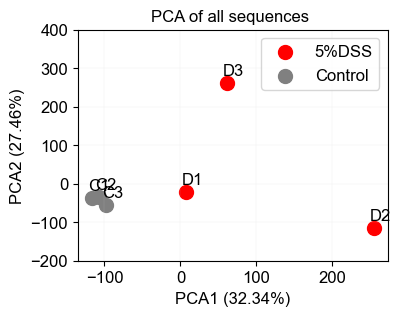

In [38]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")
base_path = "../../../../2nd_6samples_output"
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_all_seuquences.csv"), sep=",")
total = total_df.drop('sequence', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**5).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)


X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))



pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)


pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)


pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']


plt.figure(figsize=(4, 3))
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1'], subset['PC2'], label=group, color=colors[group], s=100)


for i, row in pca_df.iterrows():
    plt.text(row['PC1']-5, row['PC2']+20, row['Sample'],fontproperties=arial_font) 


plt.title("PCA of all sequences ",fontproperties=arial_font)
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)',fontproperties=arial_font)
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)',fontproperties=arial_font)

plt.legend(prop=arial_font)

plt.ylim(-200, 400)
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("figure2_B.pdf", format="pdf", bbox_inches="tight")
